# 1 · See: is the ocean data trustworthy?

**Syllabus:** Module 2 (import, select, filter, group, missing data, plots) and Module 3
(descriptive statistics, outliers, correlation).

Before predicting anything, we look hard at the data. Three sources describe the Bay of
Bengal in August 2018:

| Source | What it is | How we got it |
|---|---|---|
| **INCOIS analysis** | A gridded estimate of temperature, 1° × 1°, 24 depths, every 10 days, made by INCOIS from Argo floats | INCOIS ERDDAP server |
| **Argo floats** | Robots that dive to 2,000 m and measure temperature on the way up | Ifremer ERDDAP server |
| **Glider ru29** | An underwater glider that zig-zags through the water. Its data was *not* used to make the INCOIS analysis, so it is an independent judge | IOOS Glider DAC |

The questions: what is missing and why, what does a normal value look like, which
values are impossible, and does the gridded analysis agree with the instruments?

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import common as C

C.style()
pd.set_option("display.width", 120)

## 1.1 Import and first look

In [2]:
grid = pd.read_csv(C.DATA / "vvater_incois_analysis.csv.gz", parse_dates=["time"])
grid = grid.rename(columns={"ZAX": "depth", "TEMP": "temp", "TERR": "temp_error"})
argo = pd.read_csv(C.DATA / "vvater_argo.csv.gz", parse_dates=["time"], low_memory=False)
glider = pd.read_csv(C.DATA / "vvater_glider.csv.gz", parse_dates=["time"])

for name, df in [("INCOIS analysis", grid), ("Argo levels", argo), ("Glider levels", glider)]:
    print(f"{name:16s} {df.shape[0]:>7,} rows × {df.shape[1]} columns")
grid.head()

INCOIS analysis  136,344 rows × 6 columns
Argo levels       40,062 rows × 16 columns
Glider levels     26,189 rows × 9 columns


,time,depth,latitude,longitude,temp,temp_error
0,2018-06-30,5.0,5.5,78.5,28.535,0.0
1,2018-06-30,5.0,5.5,79.5,28.532,0.0
2,2018-06-30,5.0,5.5,80.5,28.575,0.1
3,2018-06-30,5.0,5.5,81.5,28.636,0.2
4,2018-06-30,5.0,5.5,82.5,28.688,0.2


In [3]:
grid.dtypes

time          datetime64[ns]
depth                float64
latitude             float64
longitude            float64
temp                 float64
temp_error           float64
dtype: object

### A cleaning problem, found on import

Pandas warned that one Argo column has *mixed types*. The QC flag column holds the
number `1`, the text `"1"` and blanks side by side, because the server writes the
flag as text for some floats. Counting values as they come gives the same flag twice:

In [4]:
argo["temp_adjusted_qc"].value_counts(dropna=False)

temp_adjusted_qc
1    37799
4     1776
       478
3        9
Name: count, dtype: int64

In [5]:
for col in ["temp_qc", "temp_adjusted_qc"]:
    argo[col] = pd.to_numeric(argo[col], errors="coerce").astype("Int64")
argo["temp_adjusted_qc"].value_counts(dropna=False)

temp_adjusted_qc
1       37799
4        1776
<NA>      478
3           9
Name: count, dtype: Int64

Argo gives two temperatures: the raw value, and an *adjusted* value that experts
corrected later. We use the adjusted value where it exists, and the raw one otherwise.
QC flags 1 and 2 mean "good" and "probably good". Anything else is rejected, and
rejected values are **counted, not silently deleted**.

In [6]:
use_adj = argo["temp_adjusted"].notna()
argo["T"] = np.where(use_adj, argo["temp_adjusted"], argo["temp"])
argo["qc"] = np.where(use_adj, argo["temp_adjusted_qc"].fillna(9), argo["temp_qc"].fillna(9)).astype(int)
argo["good"] = argo["qc"].isin([1, 2])
argo["depth"] = argo["pres_adjusted"].fillna(argo["pres"])   # 1 dbar ≈ 1 m (within 1% to 2,000 m)
argo["profile"] = argo["platform_number"].astype(str) + "_" + argo["cycle_number"].astype(str)

## 1.2 Missing data: half the grid is empty, and that is correct

Empty cells overall: 50.1%


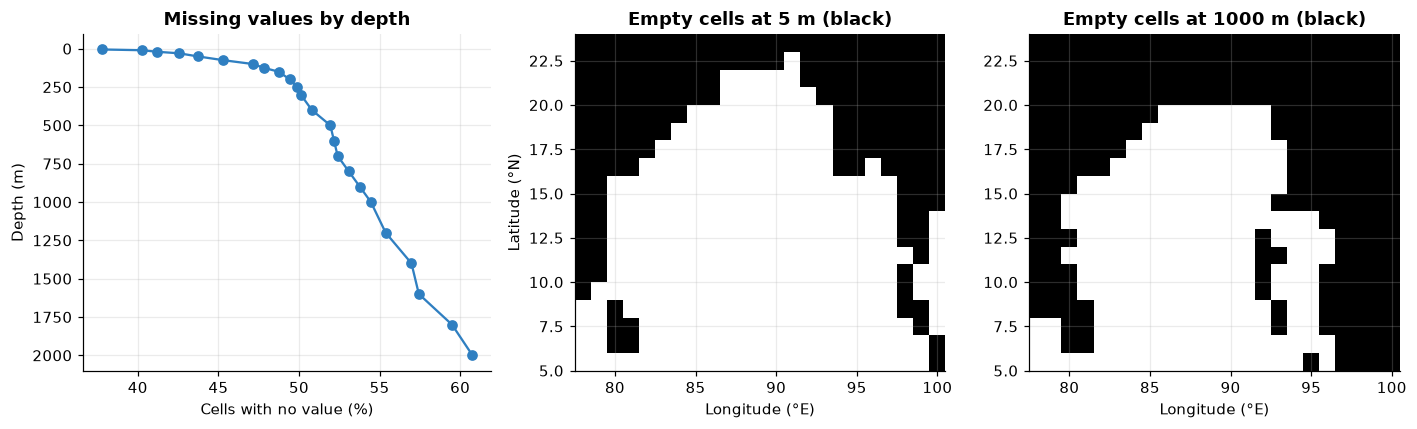

In [7]:
missing_share = grid["temp"].isna().mean()
by_depth = grid.groupby("depth")["temp"].apply(lambda s: s.isna().mean() * 100)
print(f"Empty cells overall: {missing_share:.1%}")

fig, axes = plt.subplots(1, 3, figsize=(13, 4), gridspec_kw={"width_ratios": [1.1, 1, 1]})
axes[0].plot(by_depth.values, by_depth.index, marker="o", color=C.PALETTE["course"])
axes[0].invert_yaxis(); axes[0].set_xlabel("Cells with no value (%)"); axes[0].set_ylabel("Depth (m)")
axes[0].set_title("Missing values by depth")
step = grid["time"].min()
for ax, z in zip(axes[1:], [5, 1000]):
    m = grid[(grid["time"] == step) & (grid["depth"] == z)].pivot(index="latitude", columns="longitude", values="temp")
    ax.imshow(m.isna(), origin="lower", cmap="Greys", extent=[77.5, 100.5, 5, 24], aspect="auto")
    ax.set_title(f"Empty cells at {z} m (black)"); ax.set_xlabel("Longitude (°E)")
axes[1].set_ylabel("Latitude (°N)")
fig.tight_layout(); C.save(fig, "see_missing")

C.record("see.missing_share_pct", round(missing_share * 100, 1))
C.record("see.missing_at_5m_pct", round(by_depth.loc[5.0], 1))
C.record("see.missing_at_2000m_pct", round(by_depth.loc[2000.0], 1))

The map answers the question. At 5 m the empty cells are **land**: India, Sri Lanka,
Myanmar. At 1,000 m they also include the **sea floor**, the shallow shelves where
the water is not 1,000 m deep. These values are *structurally missing*: there is no
water there to measure. Filling them in (imputing) would invent ocean where there is
rock, so we leave them empty.

## 1.3 Descriptive statistics by depth

In [8]:
desc = (grid.groupby("depth")["temp"]
        .agg(count="count", mean="mean", median="median", variance="var", std="std", min="min", max="max")
        .round(2))
desc.loc[[5, 50, 100, 200, 500, 1000, 2000]]

,count,mean,median,variance,std,min,max
depth,,,,,,,
5.0,3536,28.51,28.56,0.44,0.67,25.91,31.25
50.0,3198,27.50,27.55,0.93,0.97,22.67,31.31
100.0,3003,21.58,21.50,6.95,2.64,9.13,44.42
200.0,2873,13.94,13.92,0.41,0.64,11.90,16.74
500.0,2730,9.99,9.97,0.08,0.29,8.74,11.26
1000.0,2587,6.63,6.62,0.02,0.14,6.27,7.06
2000.0,2229,2.83,2.86,0.05,0.23,2.39,3.41


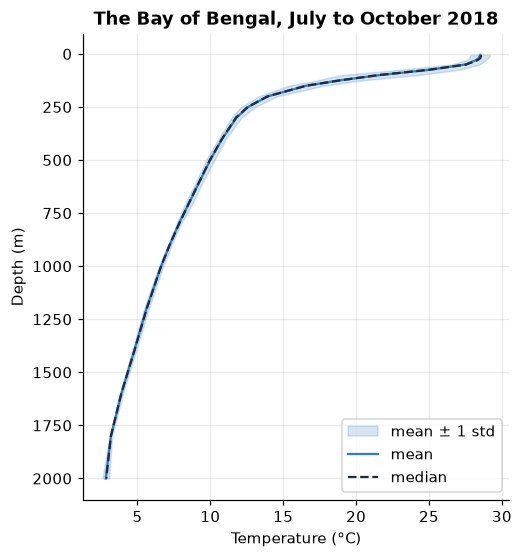

In [9]:
C.record("see.descriptive", {f"{int(z)}m": desc.loc[z, ["mean", "median", "std", "min", "max"]].to_dict()
                             for z in [5, 100, 500, 1000, 2000]})

fig, ax = plt.subplots(figsize=(5, 5.5))
ax.fill_betweenx(desc.index, desc["mean"] - desc["std"], desc["mean"] + desc["std"],
                 color=C.PALETTE["course"], alpha=0.2, label="mean ± 1 std")
ax.plot(desc["mean"], desc.index, color=C.PALETTE["course"], label="mean")
ax.plot(desc["median"], desc.index, "--", color=C.PALETTE["glorys"], label="median")
ax.invert_yaxis(); ax.set_xlabel("Temperature (°C)"); ax.set_ylabel("Depth (m)")
ax.set_title("The Bay of Bengal, July to October 2018"); ax.legend()
C.save(fig, "see_mean_profile")

Warm water (about 29 °C) sits on top of cold water (about 2.5 °C at 2,000 m). The
temperature drops fastest between roughly 50 and 200 m: that layer is the
**thermocline**. The spread (std) is largest there too, because the thermocline moves
up and down from place to place. Below 1,000 m the ocean barely varies.

## 1.4 Outliers: water that cannot be that hot

Two ways to flag an outlier:

1. **Statistical (IQR rule):** further than 1.5 × IQR beyond the box in a box plot.
   It flags anything *unusual*, real or not.
2. **Physical (Argo global range test):** sea water anywhere on Earth lies between
   −2.5 and 40 °C. It is a published rule, and it flags only the *impossible*.

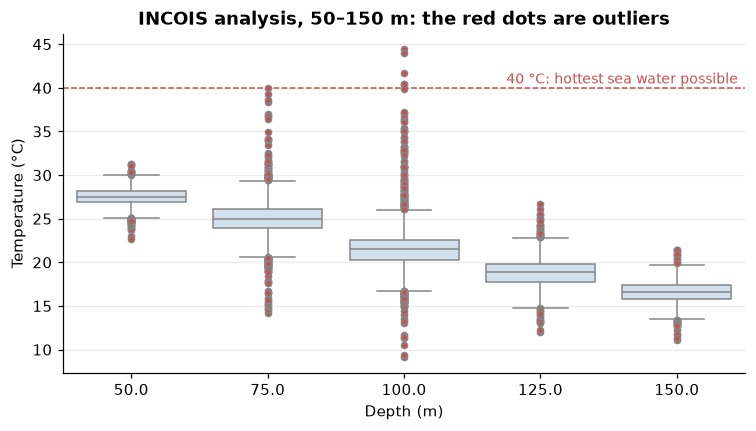

In [10]:
sub = grid[grid["depth"].isin([50, 75, 100, 125, 150])].dropna(subset=["temp"])
fig, ax = plt.subplots(figsize=(8, 4))
sns.boxplot(data=sub, x="depth", y="temp", color="#cfe0f1", flierprops={"markerfacecolor": C.PALETTE["accent"], "markersize": 4}, ax=ax)
ax.axhline(40, color=C.PALETTE["accent"], ls="--", lw=1)
ax.text(4.45, 40.5, "40 °C: hottest sea water possible", ha="right", color=C.PALETTE["accent"], fontsize=9)
ax.set_xlabel("Depth (m)"); ax.set_ylabel("Temperature (°C)")
ax.set_title("INCOIS analysis, 50–150 m: the red dots are outliers")
C.save(fig, "see_outliers")

In [11]:
valid = grid.dropna(subset=["temp"])
q1, q3 = valid.groupby("depth")["temp"].transform(lambda s: s.quantile(0.25)), valid.groupby("depth")["temp"].transform(lambda s: s.quantile(0.75))
iqr_flag = (valid["temp"] < q1 - 1.5 * (q3 - q1)) | (valid["temp"] > q3 + 1.5 * (q3 - q1))
range_flag = (valid["temp"] < -2.5) | (valid["temp"] > 40)
bad = valid[range_flag].sort_values("temp", ascending=False)
print(f"Cells checked: {len(valid):,}")
print(f"IQR rule flags:   {iqr_flag.sum():,}  (unusual)")
print(f"Range test flags: {range_flag.sum():,}  (impossible)")
bad[["time", "depth", "latitude", "longitude", "temp", "temp_error"]]

Cells checked: 68,022
IQR rule flags:   2,072  (unusual)
Range test flags: 6  (impossible)


,time,depth,latitude,longitude,temp,temp_error
23616,2018-07-20,100.0,5.5,96.5,44.423,0.5
23617,2018-07-20,100.0,5.5,97.5,43.968,0.5
23614,2018-07-20,100.0,5.5,94.5,41.741,0.3
23639,2018-07-20,100.0,6.5,96.5,40.422,0.5
23640,2018-07-20,100.0,6.5,97.5,40.386,0.5
23179,2018-07-20,75.0,5.5,96.5,40.038,0.5


In [12]:
hot_deep = valid[(valid["depth"] >= 50) & (valid["temp"] > 35) & ~range_flag]
C.record("see.outliers", {"cells_checked": len(valid), "iqr_flagged": int(iqr_flag.sum()),
                          "range_test_failed": int(range_flag.sum()), "max_temp": float(valid["temp"].max()),
                          "max_temp_depth_m": float(bad["depth"].iloc[0]), "max_temp_step": str(bad["time"].iloc[0].date()),
                          "pass_range_but_above_35_below_50m": len(hot_deep)})
print(f"Pass the range test but read above 35 °C below 50 m: {len(hot_deep)}")

Pass the range test but read above 35 °C below 50 m: 18


The INCOIS analysis contains water at **44.4 °C** 75–100 m down. No ocean on Earth is
that hot, let alone below the surface. The IQR rule flags thousands of cells, most of
them real thermocline variation. The range test flags only a handful, and all of them
are impossible. More cells read 35–40 °C below 50 m: those pass the global test,
although they are just as impossible at that depth. A *depth-aware* range would catch
them, but no published one exists, so we report them rather than invent a limit.

**Lesson:** even an official, expert-made product needs quality control. A 3D viewer
that trusted this file would show a heatwave that never happened.

## 1.5 The floats' own quality flags

In [13]:
in_box = argo["longitude"].between(78, 100) & argo["latitude"].between(5, 23)
argo_box = argo[in_box]
flags = argo_box["qc"].value_counts().sort_index()
modes = argo_box.drop_duplicates("profile")["data_mode"].value_counts()
per_float = (argo_box.groupby("platform_number")
             .agg(levels=("good", "size"), rejected=("good", lambda g: (~g).sum()))
             .assign(rejected_pct=lambda d: (100 * d["rejected"] / d["levels"]).round(1))
             .sort_values("rejected", ascending=False))
per_float["rank"] = per_float["rejected"].rank(ascending=False, method="min").astype(int)
print("QC flags (1 good, 2 probably good, 3 probably bad, 4 bad, 9 missing):"); print(flags.to_string())
print("\nProfiles by data mode (R real-time, A adjusted, D delayed-mode expert checked):"); print(modes.to_string())
per_float.head(8)

QC flags (1 good, 2 probably good, 3 probably bad, 4 bad, 9 missing):
qc
1    13546
3        4
4      522

Profiles by data mode (R real-time, A adjusted, D delayed-mode expert checked):
data_mode
D    35
A     3


,levels,rejected,rejected_pct,rank
platform_number,,,,
2902232,508,508,100.0,1
2902194,2993,5,0.2,2
2902197,2991,4,0.1,3
2902192,1989,4,0.2,3
2902154,270,3,1.1,5
2902230,535,2,0.4,6
2901895,297,0,0.0,7
2901892,299,0,0.0,7


In [14]:
C.record("see.argo", {"profiles_in_box": int(argo_box["profile"].nunique()), "levels_in_box": len(argo_box),
                      "levels_rejected": int((~argo_box["good"]).sum()),
                      "rejected_pct": round(100 * (~argo_box["good"]).mean(), 1),
                      "floats": int(argo_box["platform_number"].nunique()),
                      "data_modes": modes.to_dict()})

## 1.6 Does the analysis agree with the instruments?

For each Argo and glider profile we find the INCOIS analysis step closest in time
(within 5 days) and the grid cell containing the profile, then compare at the
analysis depths. Argo floats were *used to build* the analysis, so agreement with
Argo is a consistency check. The glider was not, so it is the honest test.

In [15]:
levels = np.sort(grid["depth"].unique())
steps = np.sort(grid["time"].unique())
cube = grid.set_index(["time", "depth", "latitude", "longitude"])["temp"]


def compare(df, tcol, zcol, vcol, key, label):
    rows = []
    for pid, p in df.groupby(key):
        p = p.dropna(subset=[zcol, vcol]).sort_values(zcol)
        if len(p) < 5:
            continue
        t0 = p[tcol].iloc[0].tz_localize(None) if p[tcol].iloc[0].tzinfo else p[tcol].iloc[0]
        k = np.argmin(np.abs(steps - np.datetime64(t0)))
        if abs((steps[k] - np.datetime64(t0)) / np.timedelta64(1, "D")) > 5:
            continue
        lat, lon = np.floor(p["latitude"].iloc[0]) + 0.5, np.floor(p["longitude"].iloc[0]) + 0.5
        z, v = p[zcol].to_numpy(), p[vcol].to_numpy()
        for zl in levels[(levels >= z.min()) & (levels <= z.max())]:
            # nearest-gap guard: do not interpolate across a gap wider than 25 m or 20% of depth
            j = np.searchsorted(z, zl)
            if j == 0 or j == len(z) or (z[j] - z[j - 1]) > max(25, 0.2 * zl):
                continue
            model = cube.get((steps[k], zl, lat, lon), np.nan)
            if np.isfinite(model):
                rows.append({"source": label, "profile": pid, "depth": zl,
                             "observed": float(np.interp(zl, z, v)), "analysis": model})
    return pd.DataFrame(rows)


argo_good = argo_box[argo_box["good"]]
glider["depth_m"] = glider["depth"]
pairs = pd.concat([compare(argo_good, "time", "depth", "T", "profile", "Argo"),
                   compare(glider.dropna(subset=["temperature"]), "time", "depth_m", "temperature", "profile_id", "Glider")])
pairs["error"] = pairs["analysis"] - pairs["observed"]
pairs["band"] = pd.cut(pairs["depth"], [0, 300, 950, 2000], labels=["0–300 m", "300–950 m", "950–2,000 m"])
rmse = (pairs.groupby(["band", "source"], observed=True)["error"].apply(lambda e: np.sqrt(np.mean(e ** 2)))
        .unstack().round(2))
counts = pairs.groupby("source")["profile"].nunique()
print("Profiles compared:", counts.to_dict())
rmse

Profiles compared: {'Argo': 36, 'Glider': 219}


source,Argo,Glider
band,,
0–300 m,1.39,2.57
300–950 m,0.23,0.47
"950–2,000 m",0.20,NaN


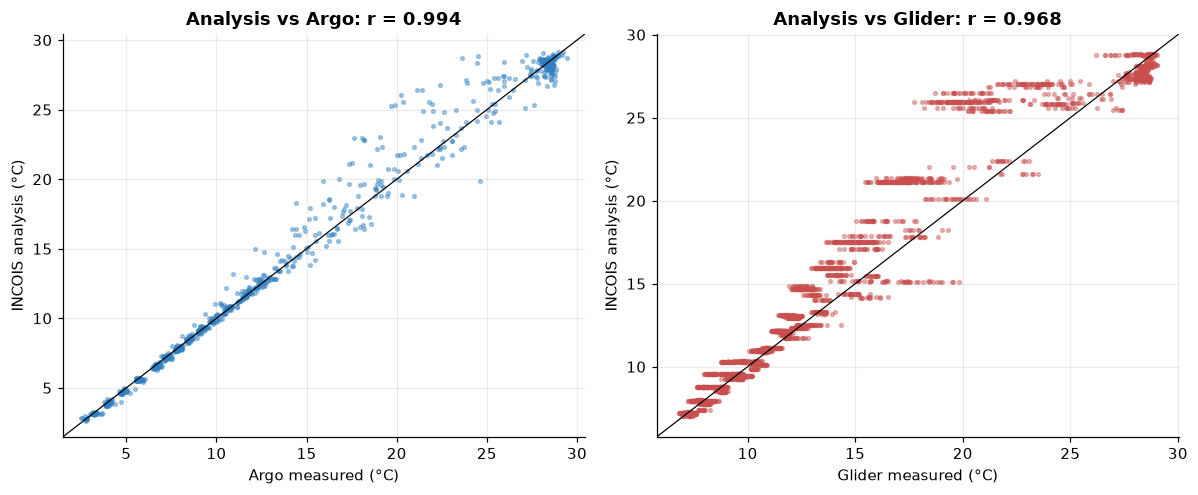

In [16]:
C.record("see.agreement", {"profiles": counts.to_dict(), "rmse_by_band": rmse.to_dict(),
                           "corr": pairs.groupby("source")[["analysis", "observed"]].corr().xs("observed", level=1)["analysis"].round(3).to_dict()})

fig, axes = plt.subplots(1, 2, figsize=(11, 4.6))
for ax, src, col in zip(axes, ["Argo", "Glider"], [C.PALETTE["course"], C.PALETTE["accent"]]):
    p = pairs[pairs["source"] == src]
    r = p[["analysis", "observed"]].corr().iloc[0, 1]
    ax.scatter(p["observed"], p["analysis"], s=6, alpha=0.4, color=col)
    lim = [p[["observed", "analysis"]].min().min() - 1, p[["observed", "analysis"]].max().max() + 1]
    ax.plot(lim, lim, color="k", lw=0.8); ax.set_xlim(lim); ax.set_ylim(lim)
    ax.set_xlabel(f"{src} measured (°C)"); ax.set_ylabel("INCOIS analysis (°C)")
    ax.set_title(f"Analysis vs {src}: r = {r:.3f}")
fig.tight_layout(); C.save(fig, "see_agreement")

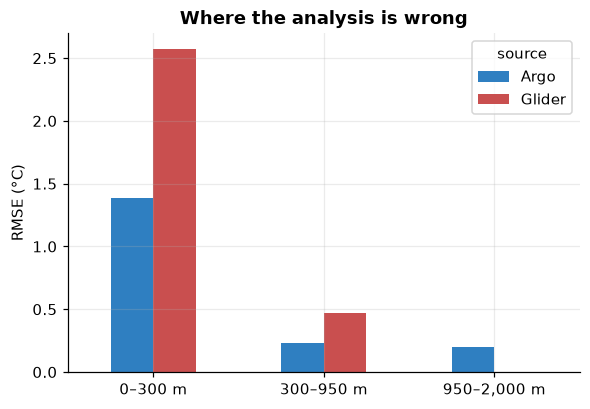

In [17]:
fig, ax = plt.subplots(figsize=(6, 4))
rmse.plot.bar(ax=ax, color=[C.PALETTE["course"], C.PALETTE["accent"]], rot=0)
ax.set_ylabel("RMSE (°C)"); ax.set_xlabel(""); ax.set_title("Where the analysis is wrong")
C.save(fig, "see_rmse_bands")

Overall the correlation looks excellent, because both columns run from 29 °C down to
3 °C. Correlation over the whole column is dominated by depth. The RMSE split by depth
tells the real story: below 300 m the analysis is good, but **in the top 300 m it is
off by degrees against the glider**. That is the layer a cyclone feeds on. An average
over all depths would have hidden it.

**What this chapter shows:** look at the data before trusting it. Missing values had a
physical cause. A published product contained impossible values. A good-looking
correlation hid a large error in exactly the layer that matters.